Training data: (27455, 784)
Testing data: (7172, 784)
Normal training data: (26337, 28, 28, 1)
Anomaly class: Y (label 24)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 14, 14, 16)          │           4,624 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 7, 7, 16)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 7, 7, 16)            │           2,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d (UpSampling2D)         │ (None, 14, 14, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 14, 14, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_1 (UpSampling2D)       │ (None, 28, 28, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 28, 28, 1)           │             289 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,193 (47.63 KB)

 Trainable params: 12,193 (47.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 32s 132ms/step - loss: 0.0133 - mae: 0.0808 - val_loss: 0.0063 - val_mae: 0.0548
Epoch 2/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 22s 117ms/step - loss: 0.0053 - mae: 0.0497 - val_loss: 0.0046 - val_mae: 0.0461
Epoch 3/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 17s 90ms/step - loss: 0.0043 - mae: 0.0446 - val_loss: 0.0041 - val_mae: 0.0431
Epoch 4/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 16s 84ms/step - loss: 0.0039 - mae: 0.0423 - val_loss: 0.0038 - val_mae: 0.0413
Epoch 5/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - loss: 0.0037 - mae: 0.0411 - val_loss: 0.0036 - val_mae: 0.0407
Epoch 6/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 25s 135ms/step - loss: 0.0035 - mae: 0.0400 - val_loss: 0.0034 - val_mae: 0.0391
Epoch 7/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 17s 91ms/step - loss: 0.0034 - mae: 0.0389 - val_loss: 0.0034 - val_mae: 0.0391
Epoch 8/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 16s 83ms/step - loss: 0.0033 - mae: 0.0383 - val_loss: 0.0032 - val_mae: 0.0376
Epoch 9/10
186/186 ━━━━━━━━━━━━━━━━━

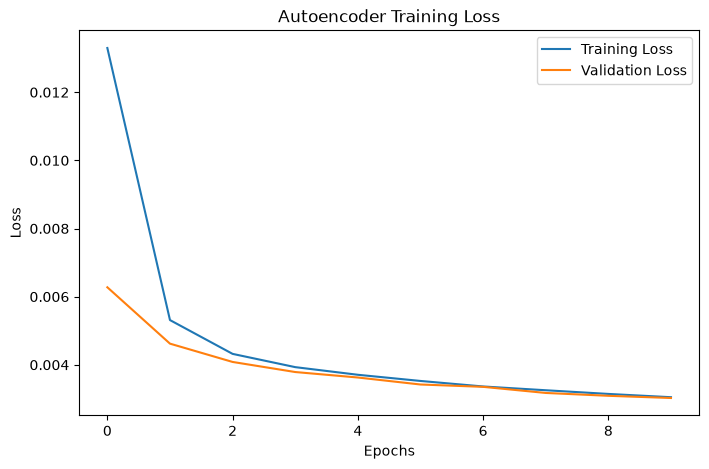

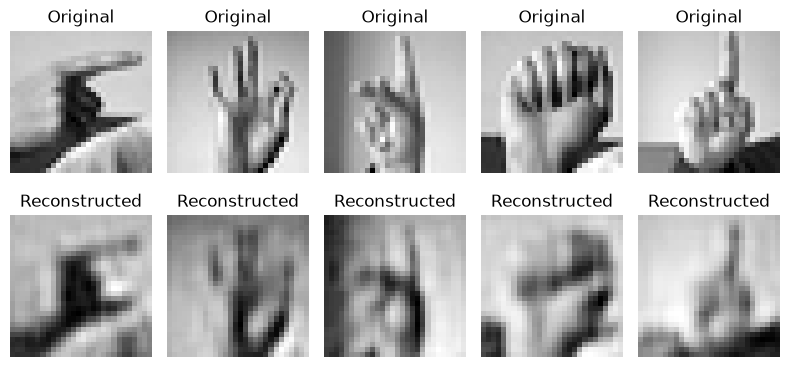

In [1]:

# 3F: Sign Language MNIST Anomaly Detection using Autoencoder

# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.optimizers import Adam


# 2. Load dataset
train_data = pd.read_csv(r'D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\AutoEncoder\Sign Language MNIST\sign_mnist_train.csv')
test_data = pd.read_csv(r'D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\AutoEncoder\Sign Language MNIST\sign_mnist_test.csv')

X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


# 3. Preprocessing
# Normalize pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0

# Reshape images to 28x28x1
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)


# 4. Select Y (label 24) as anomaly
# Train only on the remaining 23 classes

X_train_normal = X_train[y_train != 24]

print("Normal training data:", X_train_normal.shape)
print("Anomaly class: Y (label 24)")


# 5. Build Convolutional Autoencoder
input_layer = Input(shape=(28, 28, 1))

# Encoder
encoded = Conv2D(32, (3, 3), activation='relu', padding='same')(input_layer)
encoded = MaxPooling2D((2, 2), padding='same')(encoded)

encoded = Conv2D(16, (3, 3), activation='relu', padding='same')(encoded)
encoded = MaxPooling2D((2, 2), padding='same')(encoded)

# Decoder
decoded = Conv2D(16, (3, 3), activation='relu', padding='same')(encoded)
decoded = UpSampling2D((2, 2))(decoded)

decoded = Conv2D(32, (3, 3), activation='relu', padding='same')(decoded)
decoded = UpSampling2D((2, 2))(decoded)

output_layer = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(decoded)

autoencoder = Model(input_layer, output_layer)


# 6. Compile model
autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

autoencoder.summary()


# 7. Train model
history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    shuffle=True
)


# 8. Calculate reconstruction error on normal training data
train_pred = autoencoder.predict(X_train_normal)

train_errors = np.mean(
    np.square(X_train_normal - train_pred),
    axis=(1, 2, 3)
)

# Set threshold
threshold = np.percentile(train_errors, 90)

print("\nAnomaly Threshold:", threshold)


# 9. Calculate reconstruction error on test data
test_pred = autoencoder.predict(X_test)

test_errors = np.mean(
    np.square(X_test - test_pred),
    axis=(1, 2, 3)
)


# 10. Detect anomalies
# 1 = Anomaly (Y)
# 0 = Normal (other 23 classes)

y_true = (y_test == 24).astype(int)

y_pred = (test_errors > threshold).astype(int)

print("\nPredicted Anomalies:", sum(y_pred))
print("Actual Anomalies:", sum(y_true))


# 11. Evaluate model
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred, zero_division=0
))


# 12. Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


# 13. Display sample original and reconstructed images
plt.figure(figsize=(8, 4))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].squeeze(), cmap='gray')
    plt.title('Original')
    plt.axis('off')

    plt.subplot(2, 5, i + 6)
    plt.imshow(test_pred[i].squeeze(), cmap='gray')
    plt.title('Reconstructed')
    plt.axis('off')

plt.tight_layout()
plt.show()
